# 02 · Daily cycles and candidate outliers
Question: which changes remain unusual after accounting for local time of day? All accepted data contribute to this descriptive analysis. No train/test split and no predictive claims.

In [1]:
from pathlib import Path
import sys, json
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'rems_analysis.py').exists()), None)
if root is None:
    raise RuntimeError('Run this notebook inside the RoverWatch repository; see README.md.')
sys.path.insert(0, str(root))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rems_analysis import make_analysis
result, observations = make_analysis()


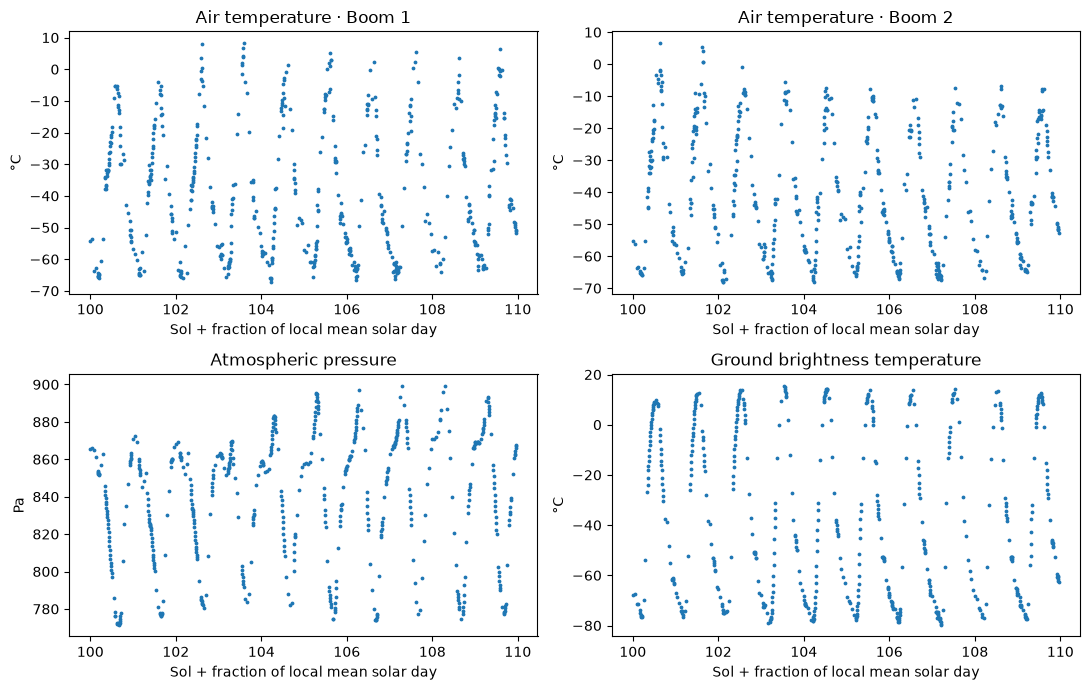

In [2]:
fig, axes = plt.subplots(2,2,figsize=(11,7))
for ax,(key,ch) in zip(axes.flat,result['channels'].items()):
    ax.scatter(observations.x,observations[key],s=3)
    ax.set(title=ch['name'],xlabel='Sol + fraction of local mean solar day',ylabel=ch['unit'])
plt.tight_layout(); plt.show()

Residual r = binned observation minus the median at the same local-time bin across available sols; require at least five sols. Score = |r − median(r)| / (1.4826 × MAD(r)). A zero MAD gives an unavailable score. Threshold 3.5 is a review heuristic, not a confidence level. Sensitivity at 3.0 and 4.5 is reported. Shared-data baselines may mask persistent anomalies; no failure annotations exist here.

In [3]:
pd.DataFrame({ch['name']:ch['summary'] for ch in result['channels'].values()}).T

,min,max,median,bins,scored,flagged,residual_center,mad,iqr_flagged,sensitivity
Air temperature · Boom 1,-67.22,8.21,-41.08,583,289,0,0.0,2.1025,0,"{'3': 4, '3.5': 0, '4.5': 0}"
Air temperature · Boom 2,-68.08,6.535,-42.68,580,286,16,0.0,1.455,0,"{'3': 22, '3.5': 16, '4.5': 4}"
Atmospheric pressure,771.66,899.29,843.795,583,288,19,0.0,4.935,0,"{'3': 27, '3.5': 19, '4.5': 8}"
Ground brightness temperature,-79.62,15.515,-43.73,584,289,12,0.0,0.675,0,"{'3': 21, '3.5': 12, '4.5': 5}"


In [4]:
pd.DataFrame(result['channels']['PRESSURE']['events'])

,sol,hour,x,value,residual,score,flagged
0,101,9.083333,101.378472,826.46,-42.895,5.862671,True
1,101,8.083333,101.336806,841.82,-37.310,5.099341,True
2,101,7.083333,101.295139,852.60,-35.585,4.863577,True
3,102,9.083333,102.378472,834.01,-35.345,4.830775,True
4,100,9.083333,100.378472,834.13,-35.225,4.814374,True
5,101,10.083333,101.420139,821.94,-35.020,4.786356,True
6,100,10.083333,100.420139,823.15,-33.810,4.620979,True
7,100,8.083333,100.336806,845.89,-33.240,4.543075,True


The pooled 1.5×IQR count is a descriptive comparison, not the preferred anomaly rule: pooling day and night can confuse expected daily extremes with unusual events. Do not remove candidate points automatically.